In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print(plt)
print(type(plt.figure))

<module 'matplotlib.pyplot' from '/opt/homebrew/anaconda3/lib/python3.14/site-packages/matplotlib/pyplot.py'>
<class 'function'>


In [4]:
#preprocess the dataset by correcting the Height column.


#Load data set
df = pd.read_csv("ABC Company Dataset.csv")

#Display the first 5 rows
df.head()


# Replace Height column with random numbers between 150 and 180

df['Height'] = np.random.randint(150,181,size=len(df))

# Display the updated Height column
print(df['Height'])

# Check the updated dataset
df.head()

0      171
1      152
2      162
3      176
4      164
      ... 
453    162
454    166
455    164
456    171
457    152
Name: Height, Length: 458, dtype: int64


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,171,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,152,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,162,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,176,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,164,231,NaN,5000000.0


                        Employee Count  Percentage
Team                                              
New Orleans Pelicans                19    4.148472
Memphis Grizzlies                   18    3.930131
New York Knicks                     16    3.493450
Milwaukee Bucks                     16    3.493450
Utah Jazz                           16    3.493450
Boston Celtics                      15    3.275109
Brooklyn Nets                       15    3.275109
Philadelphia 76ers                  15    3.275109
Toronto Raptors                     15    3.275109
Golden State Warriors               15    3.275109
Los Angeles Clippers                15    3.275109
Los Angeles Lakers                  15    3.275109
Phoenix Suns                        15    3.275109
Sacramento Kings                    15    3.275109
Chicago Bulls                       15    3.275109
Cleveland Cavaliers                 15    3.275109
Detroit Pistons                     15    3.275109
Indiana Pacers                 

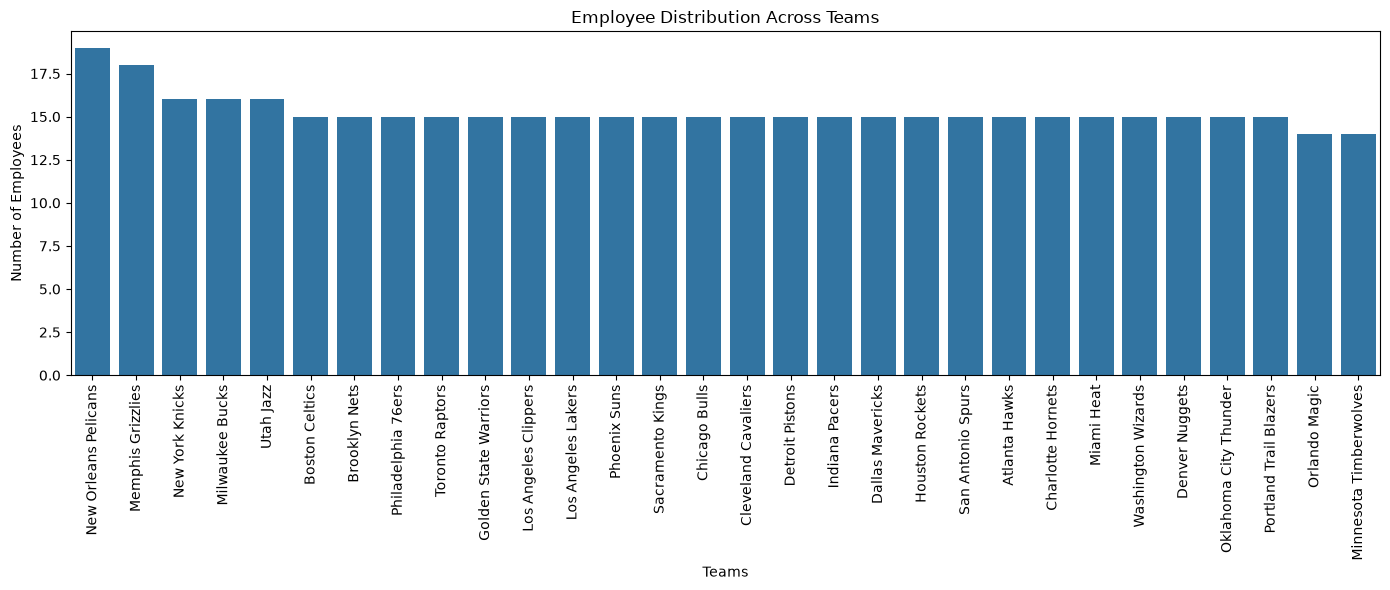

In [5]:
#Analysis Tasks:
#Determine the distribution of employees across each team and calculate the percentage split relative to the total number of employees.

team_count = df['Team'].value_counts()
# Calculate the percentage of employees in each team
team_percentage = (team_count / len(df)) * 100

# Create a summary dataframe
team_distribution = pd.DataFrame({
    'Employee Count': team_count,
    'Percentage': team_percentage
})

# Display the result
print(team_distribution)



# Count employees in each team
team_count = df['Team'].value_counts()

# Create bar chart
plt.figure(figsize=(14, 6))
sns.barplot(x=team_count.index, y=team_count.values)

# Add title and labels
plt.title("Employee Distribution Across Teams")
plt.xlabel("Teams")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)

# Display the graph
plt.tight_layout()
plt.show()


Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64

Position: C
                Name                    Team Position
7       Kelly Olynyk          Boston Celtics        C
10   Jared Sullinger          Boston Celtics        C
14      Tyler Zeller          Boston Celtics        C
23       Brook Lopez           Brooklyn Nets        C
27        Henry Sims           Brooklyn Nets        C
..               ...                     ...      ...
439    Mason Plumlee  Portland Trail Blazers        C
447      Rudy Gobert               Utah Jazz        C
455     Tibor Pleiss               Utah Jazz        C
456      Jeff Withey               Utah Jazz        C
457         Priyanka               Utah Jazz        C

[79 rows x 3 columns]

Position: PF
                 Name                    Team Position
4       Jonas Jerebko          Boston Celtics       PF
5        Amir Johnson          Boston Celtics       PF
6       Jordan Mickey          Boston Celtics       

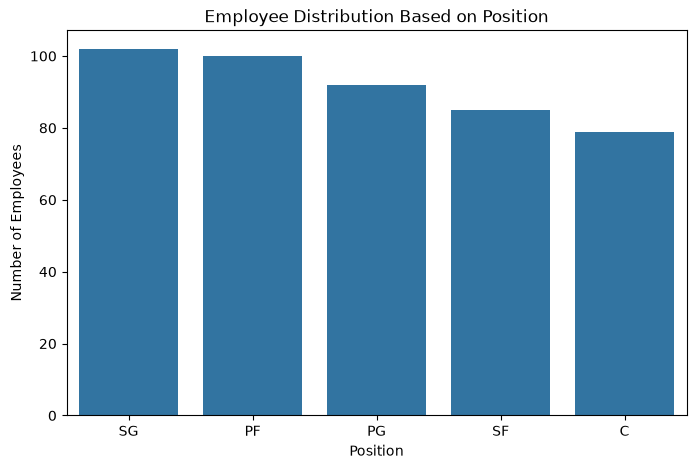

In [6]:
#Segregate employees based on their positions within the company.


# Count employees based on their positions
position_count = df['Position'].value_counts()

# Display the result
print(position_count)


# Group employees based on their positions
position_groups = df.groupby('Position')

# Display employees belonging to each position
for position, employees in position_groups:
    print("\nPosition:", position)
    print(employees[['Name', 'Team', 'Position']])

# Create count plot
plt.figure(figsize=(8, 5))
sns.countplot(x='Position', data=df, order=df['Position'].value_counts().index)

# Add title and labels
plt.title("Employee Distribution Based on Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")

# Display the graph
plt.show()

Employee Distribution by Age Group:
Age Group
18-25    200
26-30    167
31-35     68
36-40     23
Name: count, dtype: int64

Predominant Age Group: 18-25
Number of Employees: 200


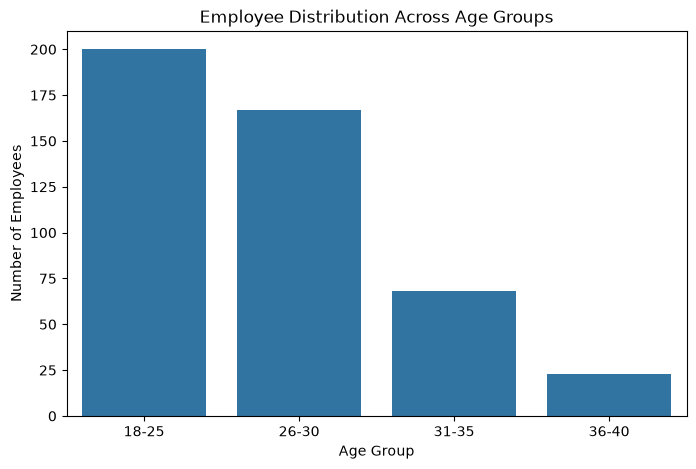

In [7]:
#Identify the predominant age group among employees.


# Define age groups
age_bins = [18, 25, 30, 35, 40]
age_labels = ['18-25', '26-30', '31-35', '36-40']

# Categorize employees into age groups
df['Age Group'] = pd.cut(df['Age'],
                         bins=age_bins,
                         labels=age_labels,
                         include_lowest=True)

# Count employees in each age group
age_group_count = df['Age Group'].value_counts().sort_index()

# Display age group distribution
print("Employee Distribution by Age Group:")
print(age_group_count)

# Identify the predominant age group
predominant_age_group = age_group_count.idxmax()
highest_count = age_group_count.max()

print("\nPredominant Age Group:", predominant_age_group)
print("Number of Employees:", highest_count)



# Count employees in each age group
age_group_count = df['Age Group'].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=age_group_count.index, y=age_group_count.values)

# Add title and labels
plt.title("Employee Distribution Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

# Display the graph
plt.show()



Team and Position Salary Expenditure:
                   Team Position      Salary
0         Atlanta Hawks        C  22756250.0
1         Atlanta Hawks       PF  23952268.0
2         Atlanta Hawks       PG   9763400.0
3         Atlanta Hawks       SF   6000000.0
4         Atlanta Hawks       SG  10431032.0
..                  ...      ...         ...
144  Washington Wizards        C  24490429.0
145  Washington Wizards       PF  11300000.0
146  Washington Wizards       PG  18022415.0
147  Washington Wizards       SF  11158800.0
148  Washington Wizards       SG  11356992.0

[149 rows x 3 columns]

Highest Salary Expenditure:
Team: Los Angeles Lakers
Position: SF
Total Salary Expenditure: 31866445.0


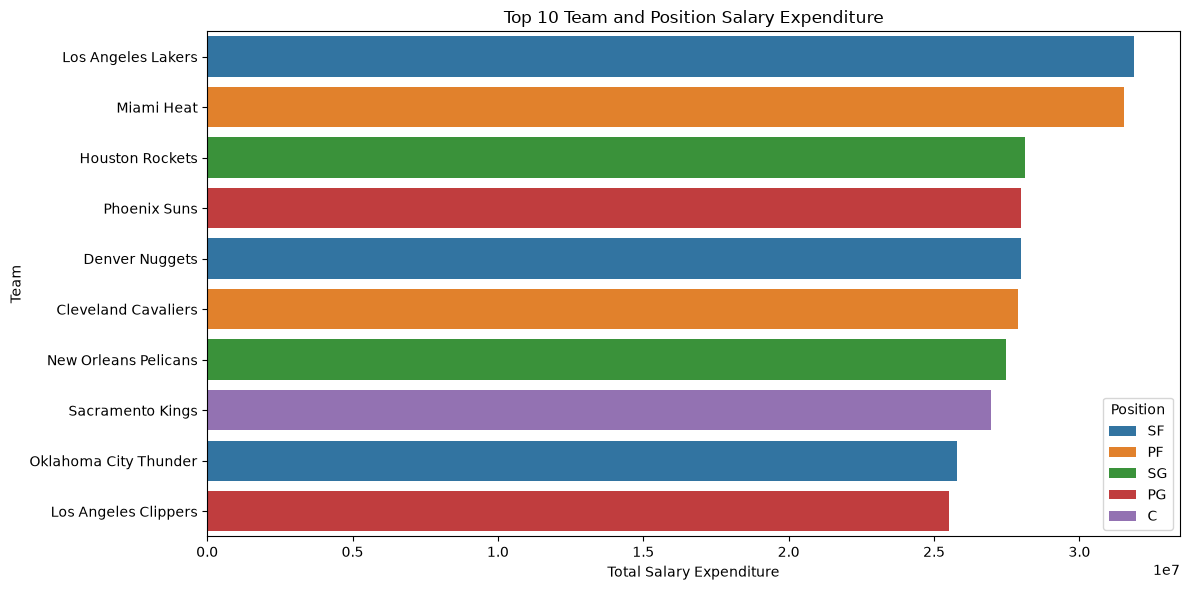

In [8]:
#Discover which team and position have the highest salary expenditure.

# Calculate total salary expenditure for each team and position
salary_expenditure = df.groupby(['Team', 'Position'])['Salary'].sum().reset_index()

# Find the team and position with the highest salary expenditure
highest_expenditure = salary_expenditure.loc[
    salary_expenditure['Salary'].idxmax()
]

# Display the result
print("Team and Position Salary Expenditure:")
print(salary_expenditure)

print("\nHighest Salary Expenditure:")
print("Team:", highest_expenditure['Team'])
print("Position:", highest_expenditure['Position'])
print("Total Salary Expenditure:", highest_expenditure['Salary'])



# Calculate salary expenditure for each team and position
salary_expenditure = df.groupby(
    ['Team', 'Position']
)['Salary'].sum().reset_index()

# Get the top 10 team-position combinations
top_10_salary = salary_expenditure.sort_values(
    by='Salary', ascending=False
).head(10)

# Create horizontal bar chart
plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_salary,
            x='Salary',
            y='Team',
            hue='Position')

# Add title and labels
plt.title("Top 10 Team and Position Salary Expenditure")
plt.xlabel("Total Salary Expenditure")
plt.ylabel("Team")

# Display the graph
plt.tight_layout()
plt.show()


Correlation between Age and Salary: 0.21400941226570971
There is a positive correlation between Age and Salary.


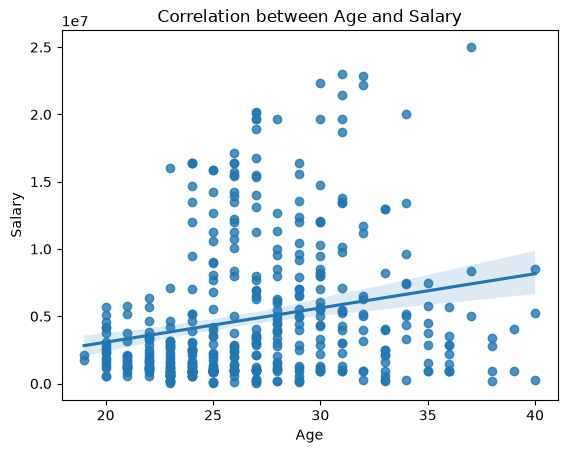

In [9]:
#Investigate if there's any correlation between age and salary, and represent it visually. (2 marks)

# Import required libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between Age and Salary
correlation = df['Age'].corr(df['Salary'])

# Display correlation
print("Correlation between Age and Salary:", correlation)

# Interpret the correlation
if correlation > 0:
    print("There is a positive correlation between Age and Salary.")
elif correlation < 0:
    print("There is a negative correlation between Age and Salary.")
else:
    print("There is no correlation between Age and Salary.")

# Create scatter plot
sns.regplot(x='Age', y='Salary', data=df)

# Add title and labels
plt.title("Correlation between Age and Salary")
plt.xlabel("Age")
plt.ylabel("Salary")

# Display the plot
plt.show()
